# **Netflix Content Analytics: An Exploratory Data Analysis of Movies & TV Shows**

# **Business Problem Statement**

In the rapidly growing streaming industry, platforms like Netflix offer thousands of movies and TV shows across different countries, genres, and content categories, making it challenging to understand content trends and audience preferences. With a wide variety of content available, identifying popular content types, genres, ratings, and production regions has become essential for improving content strategy and business growth.

Streaming platforms continuously strive to attract and retain viewers by understanding content preferences and market trends. This project focuses on analyzing Netflix content data to uncover patterns and relationships related to content types, genres, countries, release years, ratings, and content additions. The analysis aims to generate meaningful insights that can support data-driven decisions in content planning, acquisition, and investment.

# **Objective of the Analysis**

The main objective of this analysis is to explore Netflix’s content dataset and identify meaningful trends and patterns in its movies and TV shows. The analysis aims to understand the distribution of content types, popular genres, content ratings, major content-producing countries, and changes in content over the years. It also focuses on examining factors such as release year, duration, and content additions to identify notable patterns. The findings will help generate actionable insights into Netflix’s content strategy and support data-driven decisions related to content planning, acquisition, and investment.

# **Key Business Questions**

What is the distribution of Movies and TV Shows on Netflix?

Which genres have the highest number of titles on Netflix?

Which countries contribute the most content to Netflix?

How has Netflix’s content library changed over the years?

Which content ratings are most common on Netflix?

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/netflix_titles.csv")
df.shape

(8807, 12)

In [6]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [7]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [9]:
df.head(10)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",NaN,"September 24, 2021",2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...


# **Observations**

-->The dataset has a total of 8,807 rows and 12 columns.

-->show_id is the identifier column.

-->Categorical columns: type, title, director, cast, country, rating, listed_in.

-->Date column: date_added.

-->Discrete numeric column: release_year.

-->Text column: description.

-->duration contains movie duration in minutes and TV show duration in seasons.

-->The dataset contains both Movies and TV Shows.

In [10]:
# Verifying duplicates
df.duplicated().sum()

np.int64(0)

--> There are no duplicated values in the dataset

In [11]:
# Verifying missing values
round((df.isnull().sum()/len(df))*100,2)

,0
show_id,0.00
type,0.00
title,0.00
director,29.91
cast,9.37
country,9.44
date_added,0.11
release_year,0.00
rating,0.05
duration,0.03


--> Missing values were identified in six columns, with the director column having the highest proportion of missing values (29.91%), followed by country (9.44%) and cast (9.37%).

In [12]:
# Fill missing categorical information
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')

# Drop rows with very few missing values
df.dropna(subset=['date_added', 'rating', 'duration'], inplace=True)

In [13]:
round((df.isnull().sum() / len(df)) * 100, 2)

,0
show_id,0.0
type,0.0
title,0.0
director,0.0
cast,0.0
country,0.0
date_added,0.0
release_year,0.0
rating,0.0
duration,0.0


In [14]:
df.shape

(8790, 12)

# **Missing Value Handling**

Missing values in the director, cast, and country columns were replaced with "Unknown" to retain all available records. Rows with missing values in date_added, rating, and duration were removed due to their very low percentage of missing data. After this process, the dataset was rechecked, and all columns showed 0% missing values, ensuring a complete dataset for further analysis.

In [15]:
# Converting date_added column from object type to date type
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8790 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8790 non-null   object        
 1   type          8790 non-null   object        
 2   title         8790 non-null   object        
 3   director      8790 non-null   object        
 4   cast          8790 non-null   object        
 5   country       8790 non-null   object        
 6   date_added    8702 non-null   datetime64[ns]
 7   release_year  8790 non-null   int64         
 8   rating        8790 non-null   object        
 9   duration      8790 non-null   object        
 10  listed_in     8790 non-null   object        
 11  description   8790 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(10)
memory usage: 892.7+ KB


In [17]:
# Extracting year from date_added
df['added_year'] = df['date_added'].dt.year

In [18]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,added_year
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0


In [19]:
# Creating content_years column based on release year
df["content_years"] = 2025 - df["release_year"]

In [20]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,added_year,content_years
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,5
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0,4
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0,4
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0,4
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0,4


In [21]:
# Dropping show_id column
df = df.drop(columns=["show_id"])
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8790 entries, 0 to 8806
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   type           8790 non-null   object        
 1   title          8790 non-null   object        
 2   director       8790 non-null   object        
 3   cast           8790 non-null   object        
 4   country        8790 non-null   object        
 5   date_added     8702 non-null   datetime64[ns]
 6   release_year   8790 non-null   int64         
 7   rating         8790 non-null   object        
 8   duration       8790 non-null   object        
 9   listed_in      8790 non-null   object        
 10  description    8790 non-null   object        
 11  added_year     8702 non-null   float64       
 12  content_years  8790 non-null   int64         
dtypes: datetime64[ns](1), float64(1), int64(2), object(9)
memory usage: 961.4+ KB


In [22]:
df.head()

,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,added_year,content_years
0,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,5
1,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0,4
2,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0,4
3,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0,4
4,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0,4


# Content Type Analysis Visualization

In [23]:
# Check unique content types
df['type'].unique()

array(['Movie', 'TV Show'], dtype=object)

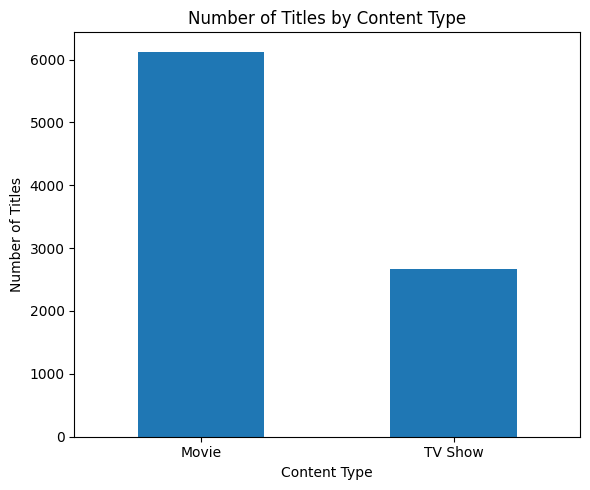

In [24]:
import matplotlib.pyplot as plt

# Count number of titles by content type
content_type = (
    df.groupby('type')['title']
    .count()
    .sort_values(ascending=False)
)

# Create Bar Chart
plt.figure(figsize=(6, 5))

content_type.plot(kind='bar')

plt.title('Number of Titles by Content Type')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

--> Movies make up the majority of Netflix's content library.

--> TV Shows represent a smaller portion of the overall content.

--> This indicates that Netflix has historically maintained a stronger focus on movie content.

In [25]:
# Which countries have the highest number of titles?
df.groupby('country')['title'].count().sort_values(ascending=False).head(10)

,title
country,
United States,2809
India,972
Unknown,829
United Kingdom,418
Japan,243
South Korea,199
Canada,181
Spain,145
France,124


In [26]:
# Which countries have the highest number of Movies and TV Shows?
df.groupby(['country', 'type'])['title'].count().sort_values(ascending=False).head(20)

country         type   
United States   Movie      2055
India           Movie       893
United States   TV Show     754
Unknown         Movie       439
                TV Show     390
United Kingdom  TV Show     212
                Movie       206
Japan           TV Show     167
South Korea     TV Show     158
Canada          Movie       122
Spain           Movie        97
Egypt           Movie        92
Nigeria         Movie        86
India           TV Show      79
Indonesia       Movie        77
Turkey          Movie        76
Japan           Movie        76
France          Movie        75
Philippines     Movie        73
Mexico          Movie        70
Name: title, dtype: int64

--> The United States has the highest number of titles in the Netflix dataset, indicating its strong contribution to Netflix's content library.

--> Other major content-producing countries contribute significantly fewer titles compared to the United States.

--> The distribution of Movies and TV Shows varies across countries, highlighting differences in content production patterns.

# Content Growth Analysis

In [27]:
# Number of titles added to Netflix by year
df.groupby('added_year')['title'].count().sort_values(ascending=False)

,title
added_year,
2019.0,1999
2020.0,1878
2018.0,1624
2021.0,1498
2017.0,1161
2016.0,415
2015.0,73
2014.0,23
2011.0,13


In [28]:
# Movies and TV Shows added by year
df.groupby(['added_year', 'type'])['title'].count()

added_year  type   
2008.0      Movie         1
            TV Show       1
2009.0      Movie         2
2010.0      Movie         1
2011.0      Movie        13
2012.0      Movie         3
2013.0      Movie         6
            TV Show       4
2014.0      Movie        19
            TV Show       4
2015.0      Movie        56
            TV Show      17
2016.0      Movie       251
            TV Show     164
2017.0      Movie       836
            TV Show     325
2018.0      Movie      1237
            TV Show     387
2019.0      Movie      1424
            TV Show     575
2020.0      Movie      1284
            TV Show     594
2021.0      Movie       993
            TV Show     505
Name: title, dtype: int64

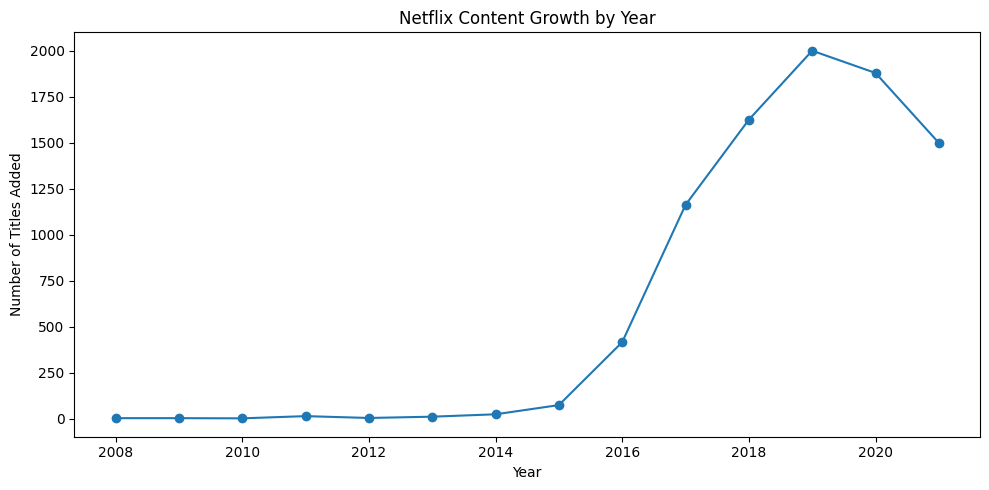

In [29]:
content_growth = df.groupby('added_year')['title'].count()

plt.figure(figsize=(10,5))
content_growth.plot(kind='line', marker='o')

plt.title('Netflix Content Growth by Year')
plt.xlabel('Year')
plt.ylabel('Number of Titles Added')

plt.tight_layout()
plt.show()

--> Netflix's content additions increased significantly during the major expansion years.

--> The analysis shows which years experienced the highest number of new titles being added.

--> Movies generally account for a larger share of yearly content additions compared with TV Shows.

--> The variation in yearly additions reflects changes in Netflix's content acquisition and expansion strategy.

# Content Rating Analysis

In [30]:
# Number of titles by content rating
df.groupby('rating')['title'].count().sort_values(ascending=False)

,title
rating,
TV-MA,3205
TV-14,2157
TV-PG,861
R,799
PG-13,490
TV-Y7,333
TV-Y,306
PG,287
TV-G,220


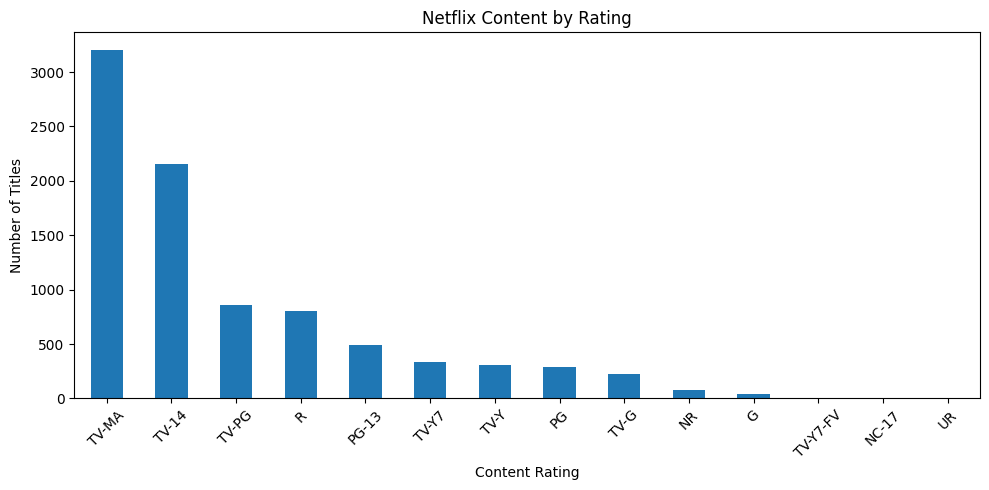

In [31]:
rating_count = df['rating'].value_counts()

plt.figure(figsize=(10,5))

rating_count.plot(kind='bar')

plt.title('Netflix Content by Rating')
plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Genre Analysis

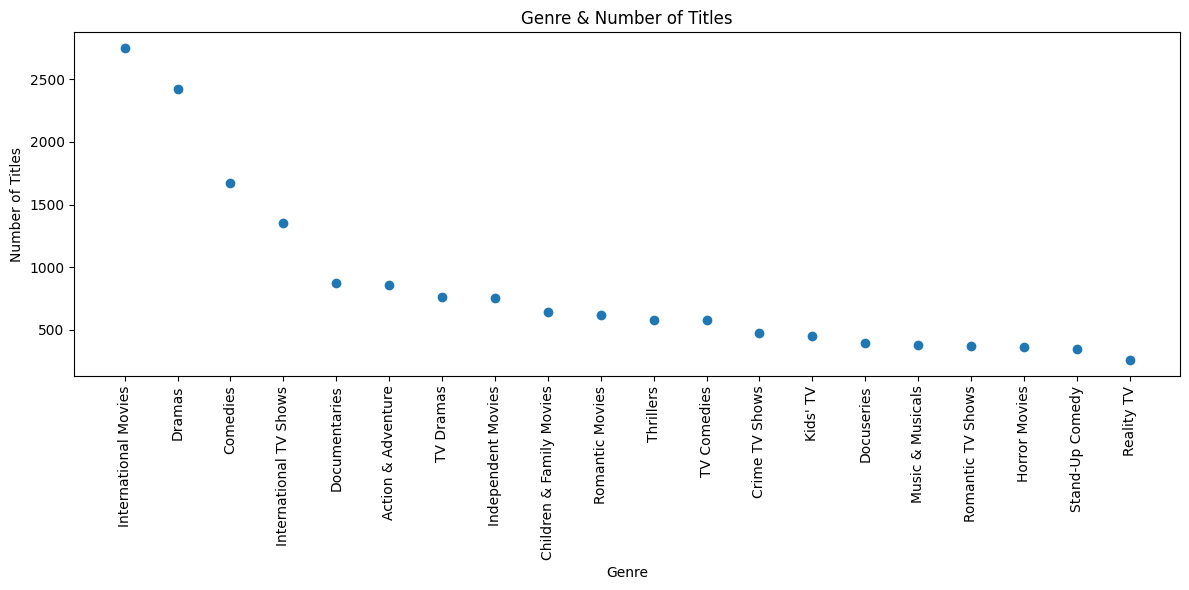

In [35]:
# Top 20 Genres

genre_count = (
    df['listed_in']
    .str.split(', ')
    .explode()
    .value_counts()
    .head(20)
)

plt.figure(figsize=(12, 6))

plt.scatter(
    genre_count.index,
    genre_count.values
)

plt.title('Genre & Number of Titles')
plt.xlabel('Genre')
plt.ylabel('Number of Titles')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

--> International Movies and Dramas have the highest number of titles in the dataset.

--> Comedies and International TV Shows also have a significant number of titles.

--> The distribution shows that Netflix has a strong presence across drama, international, and comedy-based content.

--> Genres with fewer titles represent more specialized content categories in the Netflix library.

# Duration Analysis

In [36]:
# Extract movie duration in minutes
df['movie_duration'] = df['duration'].str.extract(r'(\d+)').astype(float)

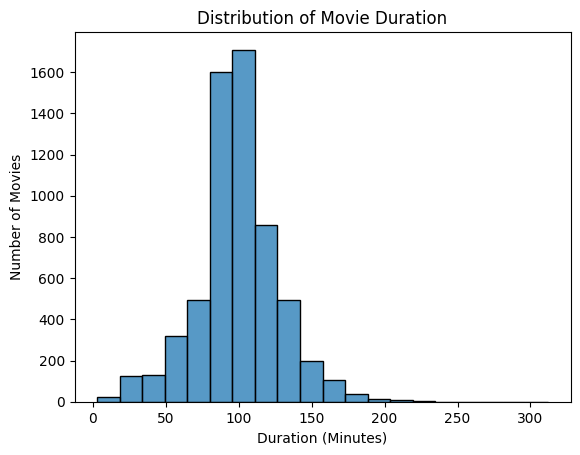

In [37]:
sns.histplot(df.loc[df['type'] == 'Movie', 'movie_duration'].dropna(), bins=20)

plt.title('Distribution of Movie Duration')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')

plt.show()

In [38]:
df.loc[df['type'] == 'Movie', 'movie_duration'].describe()

,movie_duration
count,6126.000000
mean,99.584884
std,28.283225
min,3.000000
25%,87.000000
50%,98.000000
75%,114.000000
max,312.000000


--> Most Netflix movies are concentrated within the 80–120 minute duration range.

--> The distribution shows that medium-length movies are more common in the Netflix dataset.

--> A smaller number of movies have very short or very long durations.

--> The variation in movie duration indicates that Netflix offers content with different viewing-time preferences.

# Director Analysis

In [39]:
# Top 10 directors by number of titles
director_count = (
    df[df['director'] != 'Unknown']['director']
    .value_counts()
    .head(10)
)

director_count

,count
director,
Rajiv Chilaka,19
"Raúl Campos, Jan Suter",18
Suhas Kadav,16
Marcus Raboy,16
Jay Karas,14
Cathy Garcia-Molina,13
Jay Chapman,12
Youssef Chahine,12
Martin Scorsese,12


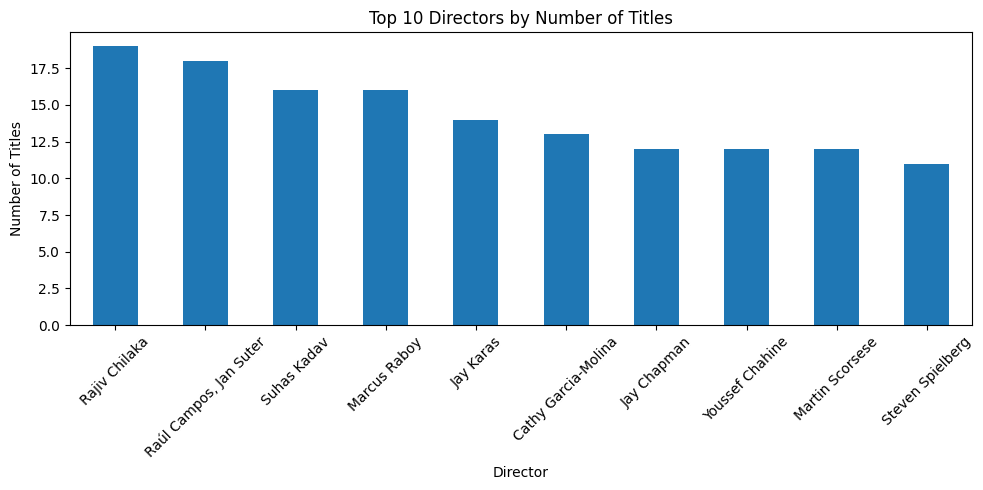

In [42]:
director_count.plot(kind='bar', figsize=(10,5))

plt.title('Top 10 Directors by Number of Titles')
plt.xlabel('Director')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

--> A small number of directors have contributed a higher number of titles to Netflix.

--> Most directors have contributed relatively few titles compared with the top directors.

--> The analysis shows that Netflix's content library is distributed across a large number of directors.

--> The top directors have a stronger presence in Netflix's overall content catalog.

# Year-wise Content Trend Analysis

In [43]:
# Number of titles added to Netflix each year
df.groupby('added_year')['title'].count().sort_values(ascending=False)

,title
added_year,
2019.0,1999
2020.0,1878
2018.0,1624
2021.0,1498
2017.0,1161
2016.0,415
2015.0,73
2014.0,23
2011.0,13


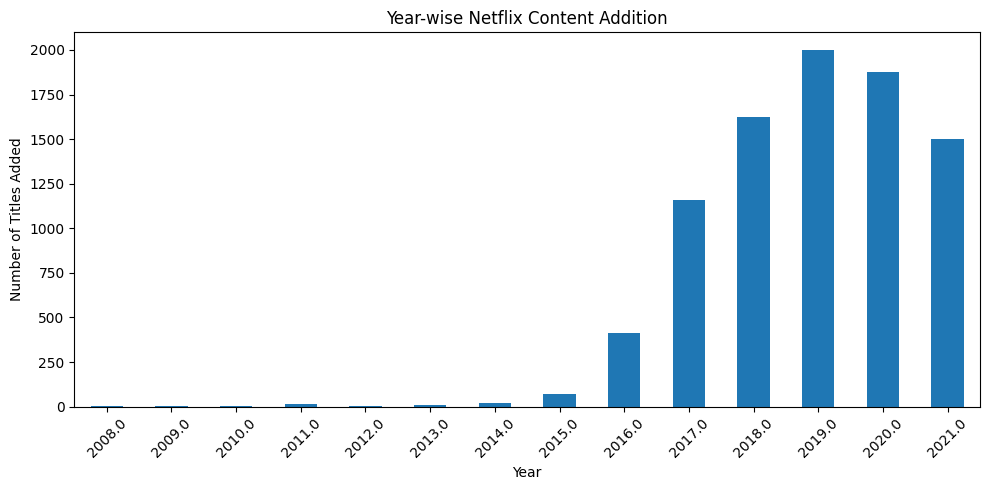

In [46]:
# Count number of titles added each year
yearly_content = df.groupby('added_year')['title'].count()

# Create bar chart
plt.figure(figsize=(10, 5))

yearly_content.plot(kind='bar')

plt.title('Year-wise Netflix Content Addition')
plt.xlabel('Year')
plt.ylabel('Number of Titles Added')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [45]:
pd.crosstab(df['added_year'], df['type'])

type,Movie,TV Show
added_year,,
2008.0,1,1
2009.0,2,0
2010.0,1,0
2011.0,13,0
2012.0,3,0
2013.0,6,4
2014.0,19,4
2015.0,56,17
2016.0,251,164


--> Netflix added the highest number of titles around 2019, showing strong content expansion during this period.

--> Content additions increased significantly from the earlier years, indicating rapid growth of Netflix's content library.

--> After the peak period, the number of titles added shows a declining trend in the latest years.

--> The trend indicates that Netflix significantly expanded its content library during the 2018–2020 period.

# Content Type & Rating Analysis

In [47]:
# Content type distribution across ratings
pd.crosstab(df['rating'], df['type'])

type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,4
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,730
TV-G,126,94
TV-MA,2062,1143


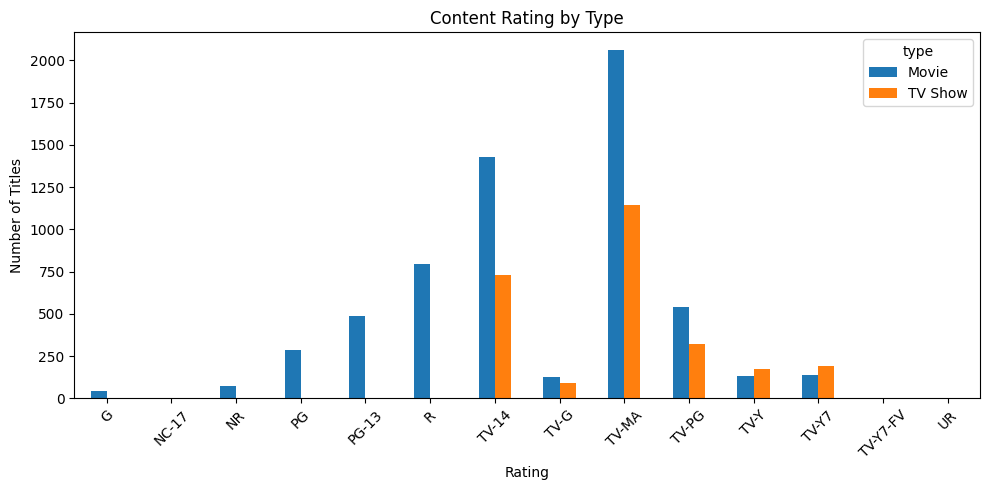

In [48]:
rating_type = pd.crosstab(df['rating'], df['type'])

rating_type.plot(kind='bar', figsize=(10, 5))

plt.title('Content Rating by Type')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

--> TV-MA is one of the most common ratings across Netflix content.

--> TV-14 also represents a significant portion of the Netflix catalog.

--> Movies and TV Shows show different rating distributions, indicating differences in their target audiences.

--> The higher presence of mature ratings suggests that Netflix has a strong focus on adult and teenage audiences.

# Correlation Analysis

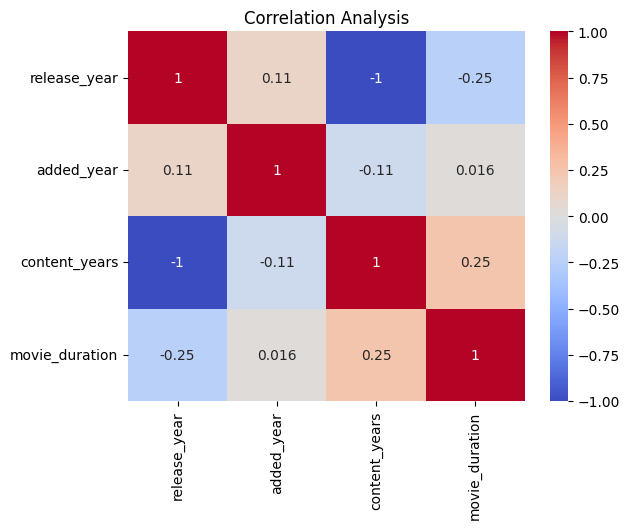

In [49]:
# Correlation Analysis

numeric_cols = ['release_year', 'added_year', 'content_years', 'movie_duration']

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Analysis')
plt.show()

--> release_year and added_year show a positive relationship, indicating newer content was generally added closer to its release.

--> content_years has an inverse relationship with release_year, reflecting the age of the content.

--> movie_duration shows weak relationships with the year-based variables, indicating little connection between movie length and release timing.

# **Key Business Insights**

--> Netflix has a larger proportion of Movies than TV Shows, indicating a strong movie-focused content library.

--> The content library is contributed by many countries, with certain countries having a significantly higher presence.

--> Netflix experienced substantial content expansion during its major growth years, particularly in the later years of the dataset.

--> TV-MA and TV-14 are among the prominent content ratings, showing strong representation of mature and teenage-oriented content.

--> Drama, International Movies, and Comedy are among the major genre categories in the Netflix catalog.

--> Most movies are concentrated around a medium-duration range, indicating a preference for standard-length movies.

# **Final Recommendations**

--> Netflix should continue investing in high-demand genres while maintaining a diverse content portfolio.

--> Content acquisition and production can be optimized by focusing on countries and regions with strong content representation and audience potential.

--> Netflix should maintain a balanced portfolio of Movies and TV Shows to serve different viewing preferences.

--> The platform can use rating trends to ensure sufficient content is available for different audience age groups.

--> Netflix should continue monitoring content addition trends to optimize future content acquisition and production strategies.

--> Content creators, genres, and formats showing strong representation in the existing catalog can be further evaluated for future content opportunities.

# **Conclusion**

This EDA project provides insights into Netflix's content library by analyzing content types, countries, genres, ratings, duration, directors, and year-wise content trends. The analysis helps identify major patterns in Netflix's content distribution and understand how the platform's library has evolved over time. Overall, the project demonstrates how Python, Pandas, data visualization, and exploratory data analysis can be used to uncover meaningful patterns and support data-driven content strategy decisions.